# Results and error analysis

Inputs: `results/runs.csv` (W&B export), `results/predictions/*.csv` (from `scripts/evaluate.py`), `results/edit_types_validation.csv` (Claude labels, validation only).

Error analysis uses validation; test is only reported.

In [1]:
import re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from art_nlp.data import load_split

FIG = Path('../results/figures'); FIG.mkdir(parents=True, exist_ok=True)
runs = pd.read_csv('../results/runs.csv')
runs['variant'] = runs.apply(lambda r: f"{r.model}-{'hyponly' if r.get('hyp_only') is True else r.format}"
    + ('-ix' if r.model == 'bag' and r.interactions is True else '')
    + (f"-{r.cell}" if r.model == 'rnn' else '') + ('-bi' if r.model == 'rnn' and r.bidirectional is True else ''), axis=1)
len(runs)

/Users/marvin/VSCode/nlp-hs26-art/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


53

## Sweeps: learning rate per variant (best validation loss)

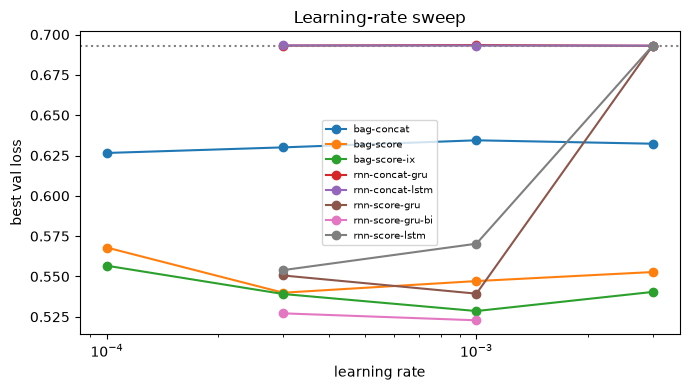

In [2]:
sw = runs[runs.tags.fillna('').str.contains('sweep')]
fig, ax = plt.subplots(figsize=(7, 4))
for v, g in sw.groupby('variant'):
    g = g.groupby('lr')['best/val/loss'].min()
    ax.plot(g.index, g.values, marker='o', label=v)
ax.set(xscale='log', xlabel='learning rate', ylabel='best val loss', title='Learning-rate sweep')
ax.axhline(0.6931, ls=':', c='grey'); ax.legend(fontsize=7); fig.tight_layout()
fig.savefig(FIG / 'lr_sweep.png', dpi=200); plt.show()

In [3]:
sw.groupby('variant')[['best/val/loss', 'best/val/acc']].agg(['min', 'max', 'count']).round(3)

best/val/loss              best/val/acc             
                           min    max count          min    max count
variant                                                              
bag-concat               0.627  0.640     8        0.626  0.663     8
bag-score                0.540  0.603     8        0.660  0.727     8
bag-score-ix             0.529  0.579     8        0.709  0.734     8
rnn-concat-gru           0.693  0.693     3        0.489  0.508     3
rnn-concat-lstm          0.693  0.693     3        0.508  0.508     3
rnn-score-gru            0.539  0.693     7        0.565  0.729     7
rnn-score-gru-bi         0.523  0.551     4        0.719  0.745     4
rnn-score-lstm           0.554  0.693     3        0.527  0.718     3

## Final models: three seeds

In [4]:
fin = runs[runs.tags.fillna('').str.contains('final|baseline')]
summary = fin.groupby('variant')['best/val/acc'].agg(['mean', 'std', 'count']).round(4)
summary

,mean,std,count
variant,,,
bag-hyponly,0.6930,0.0020,3
bag-score-ix,0.7357,0.0067,3
rnn-score-gru-bi,0.7397,0.0076,3


## Test accuracy (single evaluation of the final checkpoints)

In [5]:
def preds(split):
    out = {}
    for f in sorted(Path('../results/predictions').glob(f'*-{split}.csv')):
        out[f.name.removesuffix(f'-{split}.csv')] = pd.read_csv(f)
    return out

val, test = preds('validation'), preds('test')
name2var = dict(zip(runs.name, runs.variant))
acc = pd.DataFrame([dict(variant=name2var.get(n, n), run=n, split=s, acc=(p.pred == p.label).mean())
                    for s, d in (('validation', val), ('test', test)) for n, p in d.items()])
table = acc.groupby(['variant', 'split']).acc.agg(['mean', 'std']).unstack().round(4)
table

mean                std           
split               test validation    test validation
variant                                               
bag-hyponly       0.5220     0.6930  0.0040     0.0020
bag-score-ix      0.5346     0.7357  0.0041     0.0067
rnn-score-gru-bi  0.5453     0.7397  0.0062     0.0076

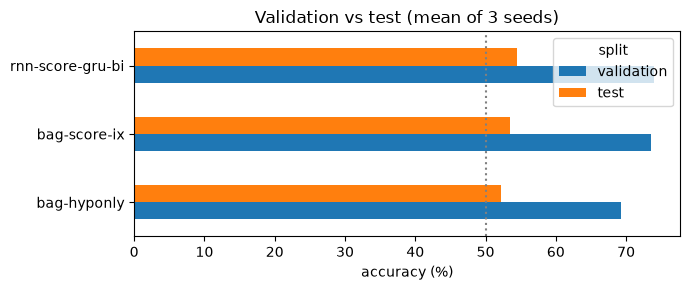

In [6]:
t = acc.groupby(['variant', 'split']).acc.mean().unstack()[['validation', 'test']]
ax = (t * 100).plot.barh(figsize=(7, 3))
ax.axvline(50, ls=':', c='grey'); ax.set(xlabel='accuracy (%)', ylabel='', title='Validation vs test (mean of 3 seeds)')
plt.tight_layout(); plt.savefig(FIG / 'val_vs_test.png', dpi=200); plt.show()

## Why is test harder? Size of the edit between the two hypotheses (label-free)

In [7]:
tok = lambda t: re.findall(r"\w+|[^\w\s]", t.lower())
def diff_bucket(split):
    d = [len(set(tok(e.hyps[0])) ^ set(tok(e.hyps[1]))) for e in load_split(split)]
    return pd.cut(pd.Series(d), [-1, 4, 8, 12, 100], labels=['0-4', '5-8', '9-12', '13+'])
buckets = {'validation': diff_bucket('validation'), 'test': diff_bucket('test')}
rows = []
for s, d in (('validation', val), ('test', test)):
    for n, p in d.items():
        for b, g in p.groupby(buckets[s]):
            rows.append(dict(variant=name2var.get(n, n), split=s, words_differing=b, acc=(g.pred == g.label).mean(), n=len(g)))
by_diff = pd.DataFrame(rows).groupby(['variant', 'split', 'words_differing'], observed=True).agg(acc=('acc', 'mean'), n=('n', 'first')).round(3)
by_diff.unstack('words_differing').reindex(columns=['0-4', '5-8', '9-12', '13+'], level=1)

acc                         n               
words_differing                0-4    5-8   9-12    13+  0-4  5-8 9-12  13+
variant          split                                                     
bag-hyponly      test        0.577  0.529  0.504  0.523   97  174  429  832
                 validation  0.695  0.694  0.670  0.707  606  253   91   50
bag-score-ix     test        0.591  0.519  0.511  0.543   97  174  429  832
                 validation  0.753  0.739  0.630  0.700  606  253   91   50
rnn-score-gru-bi test        0.560  0.592  0.538  0.537   97  174  429  832
                 validation  0.734  0.765  0.659  0.820  606  253   91   50

## Error analysis on validation by edit type

In [8]:
edits = pd.read_csv('../results/edit_types_validation.csv')
rows = []
for n, p in val.items():
    m = p.merge(edits, on='idx')
    m['correct'] = m.pred == m.label
    for key in ('edit_type', 'absurd_alone'):
        for v, g in m.groupby(key):
            rows.append(dict(variant=name2var.get(n, n), group=f'{key}={v}', acc=g.correct.mean(), n=len(g)))
by_edit = pd.DataFrame(rows).groupby(['group', 'variant']).agg(acc=('acc', 'mean'), n=('n', 'first')).acc.unstack().round(3)
by_edit['n'] = pd.DataFrame(rows).groupby('group').n.first()
by_edit

variant,bag-hyponly,bag-score-ix,rnn-score-gru-bi,n
group,,,,
absurd_alone=False,0.681,0.725,0.729,835
absurd_alone=True,0.754,0.790,0.794,165
edit_type=action,0.653,0.728,0.735,200
edit_type=entity,0.644,0.717,0.666,313
edit_type=negation,0.786,0.783,0.832,129
edit_type=other,0.688,0.679,0.751,79
edit_type=outcome,0.755,0.785,0.812,229
edit_type=time_quantity,0.640,0.627,0.633,50


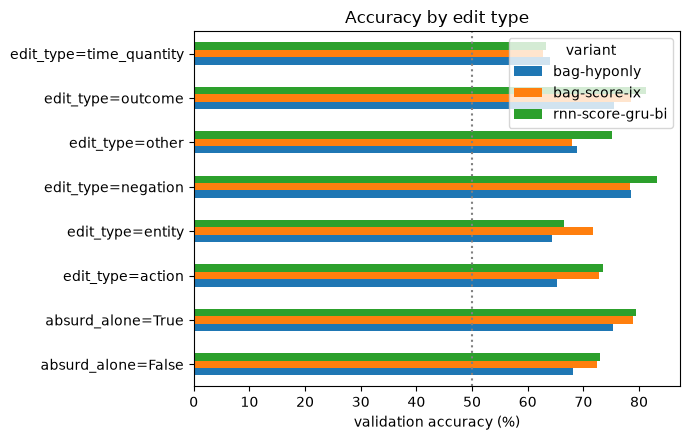

In [9]:
ax = (by_edit.drop(columns='n') * 100).plot.barh(figsize=(7, 4.5))
ax.axvline(50, ls=':', c='grey'); ax.set(xlabel='validation accuracy (%)', ylabel='', title='Accuracy by edit type')
plt.tight_layout(); plt.savefig(FIG / 'edit_types.png', dpi=200); plt.show()

## Example errors of the best RNN (validation)

In [10]:
data = load_split('validation')
rnn_runs = [n for n in val if name2var.get(n, '').startswith('rnn')]
p = val[rnn_runs[0]].merge(edits, on='idx')
wrong = p[p.pred != p.label].assign(conf=lambda d: (d.prob_h2 - 0.5).abs()).nlargest(8, 'conf')
for _, r in wrong.iterrows():
    e = data[r.idx]
    print(f"[{r.edit_type}] {e.obs1} | +{e.hyps[e.label]} | -{e.hyps[1 - e.label]} | {e.obs2}")

[outcome] May was a science teacher at a local high school. | +May was a distant and uninvolved teacher. | -May was a caring teacher. | She handed out assignments and browsed the internet all day.
[time_quantity] When I was younger my family and I would go on summer vacations. | +Lately, my family hardly talks to each other. | -Lately, my family talks to each other constantly. | Now every time summer comes around I become sad.
[outcome] Megan is the new boss at her office. | +Megan relaxed the dress code at work. | -Megan made a strict dress code. | She instantly became very well liked by the staff.
[entity] In August Billy is going overseas for the war. | +Bill made it overseas to fight the war. | -Bill made it overseas to the wedding. | Now Bill only focuses on the war, and serving his country.
[action] When my phone rang I just knew something was wrong. | +my sister needed a ride home from a bad date. | -my sister needed a break from a a job. | She was so surprised and happy to see 